# Modélisation et interprétation

Ce notebook prolonge l'analyse exploratoire conduite dans `01_eda.ipynb`. Il compare trois familles de modèles sur la tâche de détection de panne, puis analyse les déterminants des prédictions du meilleur d'entre eux.

## Hypothèse de travail

> Les modèles non linéaires (Random Forest, XGBoost) devraient détecter les pannes plus efficacement que la régression logistique, au prix d'un nombre potentiellement plus élevé de faux positifs.

Cette hypothèse est évaluée expérimentalement : les trois modèles sont entraînés sur les mêmes données, avec le même traitement du déséquilibre, et comparés sur les mêmes métriques.

## Protocole

1. Séparation train/test stratifiée (80 / 20), la stratification garantissant un taux de panne identique dans les deux échantillons
2. Encodage de la variable catégorielle et standardisation pour le seul modèle qui en a besoin
3. Compensation du déséquilibre par pondération des classes, appliquée identiquement aux trois modèles
4. Validation croisée stratifiée en 5 blocs sur l'échantillon d'entraînement, pour estimer la stabilité des performances
5. Évaluation sur l'échantillon de test : précision, rappel, F1-score, PR-AUC et matrice de confusion
6. Ajustement du seuil de décision à partir des prédictions hors échantillon, sans jamais consulter le jeu de test
7. Interprétation du meilleur modèle par valeurs de Shapley (SHAP)
8. Analyse des erreurs sur les faux positifs et les faux négatifs

## Choix des métriques

Le taux de panne est de 3,39 %. L'accuracy est donc écartée : prédire systématiquement l'absence de panne suffit à atteindre 96,6 %.

La **PR-AUC** (aire sous la courbe précision-rappel) est retenue comme métrique principale. Contrairement à la ROC-AUC, elle ne bénéficie pas mécaniquement de l'abondance de vrais négatifs et reflète donc fidèlement la difficulté du problème déséquilibré. Elle est en outre indépendante du seuil de décision, ce qui permet de comparer les modèles sur leur pouvoir de discrimination intrinsèque.

Le **rappel** et la **précision** sont examinés conjointement car ils traduisent l'arbitrage métier identifié en introduction : le rappel mesure la proportion de pannes effectivement détectées (une panne manquée est un arrêt de production subi), la précision mesure la proportion d'alertes justifiées (une fausse alerte est une intervention de maintenance inutile).

## 1. Préparation

In [1]:
import os
import warnings
from pathlib import Path

# Les opérations BLAS de scikit-learn émettent sur cette plateforme des avertissements
# numériques sans incidence sur les résultats. La variable d'environnement est nécessaire
# pour que le filtre s'applique aussi aux processus parallèles lancés par joblib.
os.environ["PYTHONWARNINGS"] = "ignore"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    confusion_matrix, precision_recall_curve, roc_auc_score, classification_report,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
np.seterr(all="ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

TARGET = "Machine failure"

In [2]:
df = pd.read_csv("../data/processed/ai4i2020_model.csv")
print("Dimensions :", df.shape)
print(f"Taux de panne : {df[TARGET].mean():.2%}")
df.head()

Dimensions : (10000, 7)
Taux de panne : 3.39%


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


### Normalisation des noms de colonnes

Les noms d'origine comportent des crochets (`Air temperature [K]`). XGBoost les rejette : son format interne réserve les caractères `[`, `]` et `<` à l'encodage des conditions de branchement. Les unités sont donc replacées entre parenthèses, ce qui préserve la lisibilité des graphiques.

In [3]:
RENOMMAGE = {
    "Air temperature [K]": "Air temperature (K)",
    "Process temperature [K]": "Process temperature (K)",
    "Rotational speed [rpm]": "Rotational speed (rpm)",
    "Torque [Nm]": "Torque (Nm)",
    "Tool wear [min]": "Tool wear (min)",
}

df = df.rename(columns=RENOMMAGE)
df.columns.tolist()

['Type',
 'Air temperature (K)',
 'Process temperature (K)',
 'Rotational speed (rpm)',
 'Torque (Nm)',
 'Tool wear (min)',
 'Machine failure']

### Encodage de la variable catégorielle

`Type` prend trois modalités ordonnées par qualité croissante : `L` (*Low*), `M` (*Medium*), `H` (*High*). Elle est encodée en variables indicatrices, la modalité `H` servant de référence. Supprimer une modalité évite la colinéarité parfaite entre les indicatrices, qui rendrait les coefficients de la régression logistique non identifiables.

In [4]:
X = pd.get_dummies(df.drop(columns=[TARGET]), columns=["Type"], drop_first=True, dtype=float)
y = df[TARGET]

print("Variables explicatives après encodage :", X.shape[1])
for col in X.columns:
    print(" -", col)

Variables explicatives après encodage : 7
 - Air temperature (K)
 - Process temperature (K)
 - Rotational speed (rpm)
 - Torque (Nm)
 - Tool wear (min)
 - Type_L
 - Type_M


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Entraînement : {len(X_train):>5} observations — {y_train.sum():>3} pannes ({y_train.mean():.2%})")
print(f"Test         : {len(X_test):>5} observations — {y_test.sum():>3} pannes ({y_test.mean():.2%})")

Entraînement :  8000 observations — 271 pannes (3.39%)
Test         :  2000 observations —  68 pannes (3.40%)


La stratification préserve le taux de panne dans les deux échantillons. Sans elle, le faible effectif de la classe positive exposerait à un déséquilibre accidentel entre train et test, rendant les performances mesurées peu fiables.

### Traitement du déséquilibre

Avec 28,5 observations négatives pour une positive, un modèle optimisant une fonction de perte non pondérée a intérêt à ignorer la classe minoritaire. Les trois modèles reçoivent donc une pondération inversement proportionnelle à la fréquence des classes — `class_weight="balanced"` pour la régression logistique et la forêt aléatoire, `scale_pos_weight` pour XGBoost. Le traitement étant identique pour les trois, la comparaison reste équitable.

Un ré-échantillonnage de type SMOTE aurait constitué une alternative ; la pondération lui est préférée ici car elle n'introduit pas d'observations synthétiques dans un jeu de données déjà simulé.

In [6]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

scale_pos_weight = 28.52


## 2. Définition des modèles

La régression logistique est encapsulée dans un pipeline incluant une standardisation : les variables explicatives s'étendent sur des échelles très différentes (température autour de 300 K, vitesse de rotation autour de 1 500 rpm), ce qui pénaliserait la convergence et fausserait la régularisation.

Les modèles à base d'arbres n'ont pas besoin de standardisation : ils procèdent par seuils sur chaque variable prise isolément, opération invariante à toute transformation monotone. Ils sont donc entraînés sur les variables dans leurs unités d'origine, ce qui rendra les graphiques SHAP directement lisibles.

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
        )),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

for nom in models:
    print("-", nom)

- Logistic Regression
- Random Forest
- XGBoost


## 3. Validation croisée sur l'échantillon d'entraînement

Avant toute évaluation sur le jeu de test, une validation croisée stratifiée en 5 blocs estime la PR-AUC de chaque modèle et sa variabilité. L'écart-type entre blocs indique si l'écart de performance entre modèles est robuste ou relève du bruit d'échantillonnage.

In [8]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
resultats_cv = {}

for nom, modele in models.items():
    scores = cross_val_score(modele, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    resultats_cv[nom] = scores
    print(f"{nom:<22} PR-AUC = {scores.mean():.4f} (± {scores.std():.4f})")

Logistic Regression    PR-AUC = 0.4408 (± 0.0299)


Random Forest          PR-AUC = 0.7498 (± 0.0372)
XGBoost                PR-AUC = 0.7513 (± 0.0357)


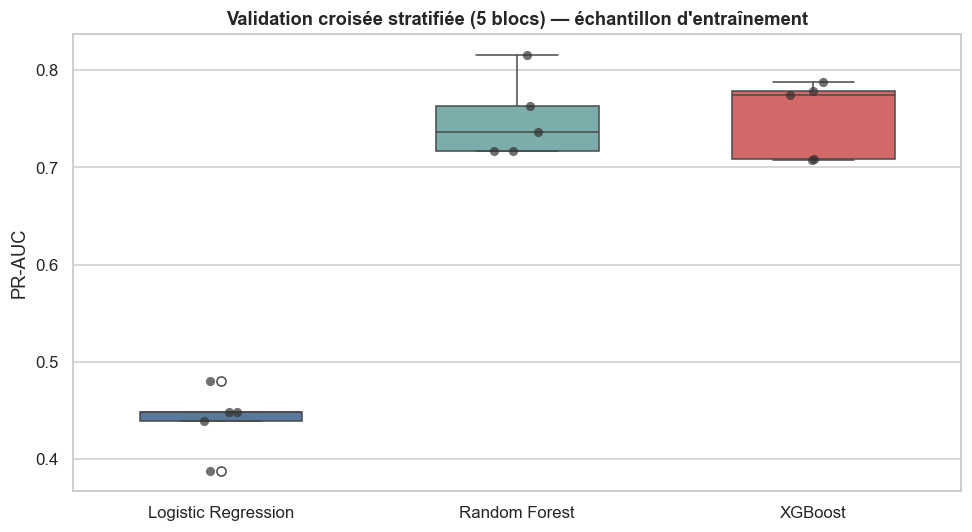

In [9]:
cv_df = pd.DataFrame(resultats_cv)
cv_long = cv_df.melt(var_name="Modèle", value_name="PR-AUC")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=cv_long, x="Modèle", y="PR-AUC", hue="Modèle", legend=False,
            palette=["#4C78A8", "#72B7B2", "#E45756"], ax=ax, width=0.55)
sns.stripplot(data=cv_long, x="Modèle", y="PR-AUC", color="#333333",
              size=6, alpha=0.7, jitter=0.08, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("PR-AUC")
ax.set_title(f"Validation croisée stratifiée ({N_SPLITS} blocs) — échantillon d'entraînement",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_validation_croisee.png", bbox_inches="tight")
plt.show()

La validation croisée sépare nettement deux groupes :

| Modèle | PR-AUC moyenne | Écart-type |
|---|---|---|
| Logistic Regression | 0,441 | ± 0,030 |
| Random Forest | 0,750 | ± 0,037 |
| XGBoost | 0,751 | ± 0,036 |

L'écart entre la régression logistique et les deux modèles d'ensemble dépasse largement la dispersion entre blocs : il est robuste et ne relève pas du hasard d'échantillonnage.

En revanche, l'écart entre Random Forest et XGBoost (0,001) est très inférieur à leur écart-type respectif : **à ce stade, rien ne permet de les départager.** Le jeu de test tranchera, mais cette quasi-égalité en validation croisée invite à la prudence sur l'interprétation de la différence finale.

## 4. Entraînement et évaluation sur le jeu de test

In [10]:
def evaluer(nom, modele, X_tr, y_tr, X_te, y_te, seuil=0.5):
    modele.fit(X_tr, y_tr)
    proba = modele.predict_proba(X_te)[:, 1]
    pred = (proba >= seuil).astype(int)
    return {
        "modele": nom,
        "objet": modele,
        "proba": proba,
        "pred": pred,
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "PR-AUC": average_precision_score(y_te, proba),
        "ROC-AUC": roc_auc_score(y_te, proba),
    }


resultats = [evaluer(nom, m, X_train, y_train, X_test, y_test) for nom, m in models.items()]

In [11]:
COLONNES = ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]

tableau = pd.DataFrame(resultats).set_index("modele")[COLONNES].round(4)
tableau.index.name = "Modèle"
tableau

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modèle,,,,,
Logistic Regression,0.1418,0.8235,0.2419,0.3817,0.9070
Random Forest,0.8077,0.6176,0.7000,0.7735,0.9709
XGBoost,0.6087,0.8235,0.7000,0.8132,0.9723


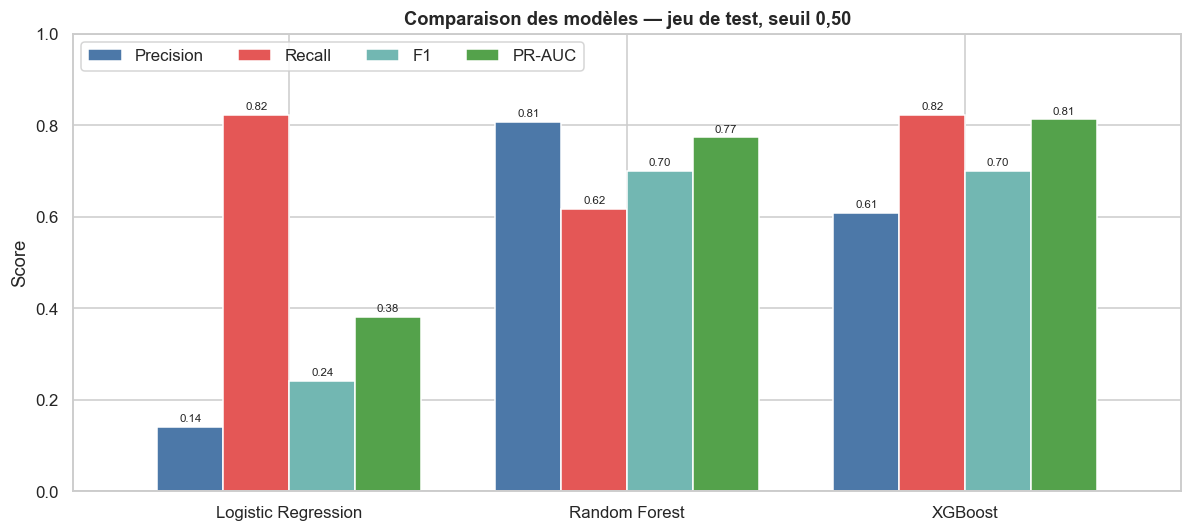

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
tableau[["Precision", "Recall", "F1", "PR-AUC"]].plot(
    kind="bar", ax=ax, color=["#4C78A8", "#E45756", "#72B7B2", "#54A24B"], width=0.78, edgecolor="white"
)
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_title("Comparaison des modèles — jeu de test, seuil 0,50", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", ncol=4, frameon=True)
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7.5, padding=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_comparaison_modeles.png", bbox_inches="tight")
plt.show()

### Lecture du tableau comparatif

| Modèle | Precision | Recall | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0,142 | 0,824 | 0,242 | 0,382 | 0,907 |
| Random Forest | 0,808 | 0,618 | 0,700 | 0,774 | 0,971 |
| XGBoost | 0,609 | 0,824 | 0,700 | **0,813** | 0,972 |

**La régression logistique échoue, mais pas là où on l'attendait.** Son rappel est excellent (0,824, à égalité avec XGBoost) : elle détecte autant de pannes que le meilleur modèle. C'est sa précision qui s'effondre à 0,142 — moins d'une alerte sur sept est justifiée. Incapable de tracer une frontière non linéaire, elle compense en élargissant massivement sa zone de décision.

**Random Forest et XGBoost obtiennent le même F1 (0,700) par des voies opposées.** Random Forest privilégie la précision (0,808) au détriment du rappel (0,618) ; XGBoost fait l'inverse (0,609 et 0,824). Le F1 identique masque donc deux compromis radicalement différents, ce qui illustre la limite d'une métrique agrégée prise isolément.

**La PR-AUC départage : XGBoost l'emporte (0,813 contre 0,774).** Cette métrique étant indépendante du seuil, elle mesure le pouvoir de discrimination intrinsèque, indépendamment du compromis retenu.

**Comparaison instructive entre ROC-AUC et PR-AUC.** Les trois modèles affichent une ROC-AUC élevée — jusqu'à 0,907 pour la régression logistique, qui n'émet pourtant qu'une alerte justifiée sur sept. La ROC-AUC intègre le taux de vrais négatifs, abondants ici, et donne donc une image flatteuse d'un modèle inexploitable. La PR-AUC, elle, chute à 0,382 et reflète correctement la réalité. **C'est la démonstration empirique de la raison pour laquelle la PR-AUC a été retenue comme métrique principale.**

## 5. Matrices de confusion

Les métriques agrégées masquent la nature des erreurs. Les matrices de confusion explicitent le compromis réellement opéré par chaque modèle.

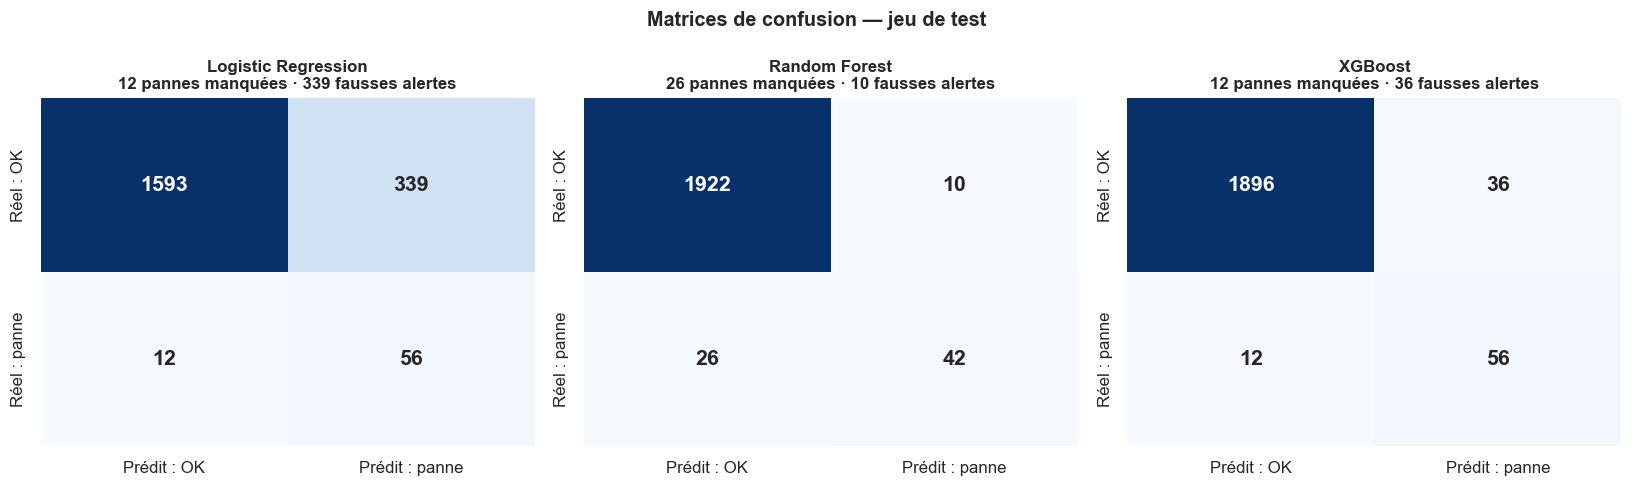

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, res in zip(axes, resultats):
    cm = confusion_matrix(y_test, res["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 14, "weight": "bold"},
                xticklabels=["Prédit : OK", "Prédit : panne"],
                yticklabels=["Réel : OK", "Réel : panne"])
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{res['modele']}\n{fn} pannes manquées · {fp} fausses alertes",
                 fontsize=11, fontweight="bold")

fig.suptitle("Matrices de confusion — jeu de test", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_matrices_confusion.png", bbox_inches="tight")
plt.show()

In [14]:
detail = []
for res in resultats:
    tn, fp, fn, tp = confusion_matrix(y_test, res["pred"]).ravel()
    detail.append({
        "Modèle": res["modele"],
        "Vrais négatifs": tn,
        "Faux positifs": fp,
        "Faux négatifs": fn,
        "Vrais positifs": tp,
        "Pannes détectées": f"{tp}/{tp + fn}",
        "Alertes émises": tp + fp,
    })

pd.DataFrame(detail).set_index("Modèle")

,Vrais négatifs,Faux positifs,Faux négatifs,Vrais positifs,Pannes détectées,Alertes émises
Modèle,,,,,,
Logistic Regression,1593,339,12,56,56/68,395
Random Forest,1922,10,26,42,42/68,52
XGBoost,1896,36,12,56,56/68,92


### Ce que révèlent les matrices de confusion

Sur 2 000 observations de test, dont 68 pannes :

| Modèle | Pannes détectées | Pannes manquées | Fausses alertes | Alertes émises |
|---|---|---|---|---|
| Logistic Regression | 56 / 68 | 12 | **339** | 395 |
| Random Forest | 42 / 68 | **26** | 10 | 52 |
| XGBoost | 56 / 68 | 12 | 36 | 92 |

Traduit en termes opérationnels : la régression logistique déclenche **395 interventions pour 56 pannes réelles**, soit près de sept déplacements de maintenance pour une panne évitée. Le dispositif serait abandonné en quelques semaines.

Random Forest présente le défaut symétrique : seulement 10 fausses alertes, mais **26 pannes passent au travers**, soit plus d'une sur trois non détectée.

XGBoost détecte autant de pannes que la régression logistique (56) en divisant le nombre de fausses alertes par près de dix (36 contre 339).

### Retour sur l'hypothèse de départ

> *Les modèles non linéaires devraient mieux détecter les pannes que la régression logistique, mais pourraient produire davantage de faux positifs.*

**La première partie est confirmée, la seconde est infirmée.**

Les modèles non linéaires discriminent effectivement bien mieux : la PR-AUC passe de 0,382 à 0,813. Mais loin de produire *davantage* de faux positifs, XGBoost en génère **neuf fois moins** que la baseline (36 contre 339).

L'explication tient à la nature de la frontière de décision. La régression logistique ne peut séparer les classes que par un hyperplan. Or l'analyse exploratoire a montré que les pannes surviennent dans **deux régimes opposés** — couple très faible et couple très élevé — et dépendent de combinaisons de conditions plutôt que de seuils univariés. Aucune frontière linéaire ne peut isoler simultanément deux régions situées aux extrémités opposées d'une même variable. Pour capter les deux groupes, le modèle est contraint d'inclure tout l'espace intermédiaire, où se trouve l'essentiel des observations saines.

Les modèles à base d'arbres, en partitionnant récursivement l'espace, isolent ces deux régions séparément sans englober la zone centrale. Ce n'est donc pas la « puissance » du modèle qui explique l'écart, mais **l'adéquation entre la forme de sa frontière de décision et la géométrie du problème.**

## 6. Courbes précision-rappel

La courbe précision-rappel décrit le comportement de chaque modèle sur l'ensemble des seuils de décision possibles, et non au seul seuil arbitraire de 0,50.

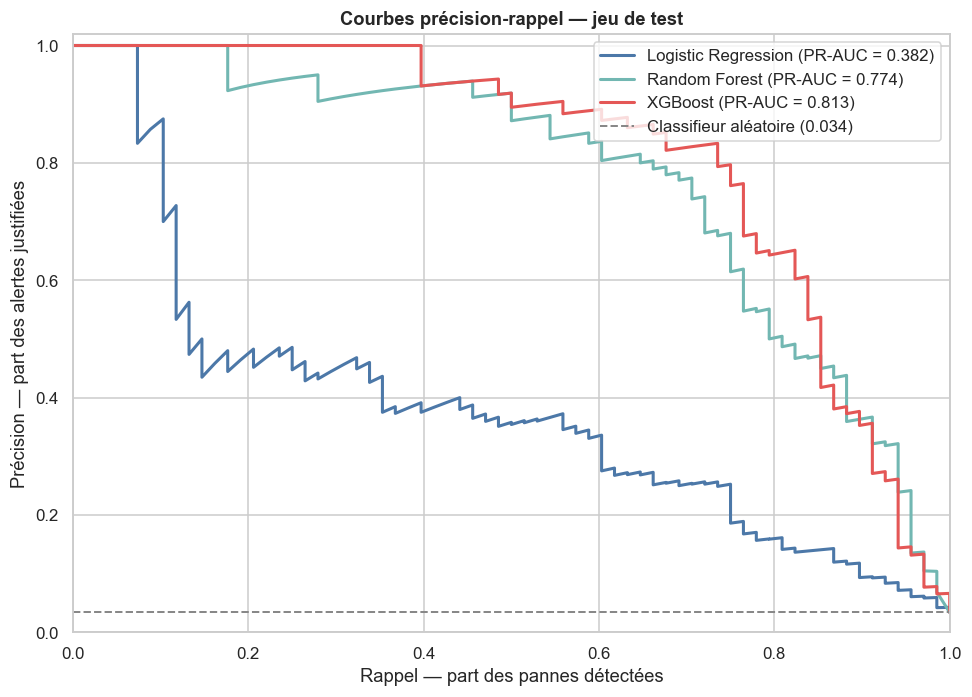

In [15]:
fig, ax = plt.subplots(figsize=(9, 6.5))
couleurs = ["#4C78A8", "#72B7B2", "#E45756"]

for res, couleur in zip(resultats, couleurs):
    prec, rec, _ = precision_recall_curve(y_test, res["proba"])
    ax.plot(rec, prec, label=f"{res['modele']} (PR-AUC = {res['PR-AUC']:.3f})",
            color=couleur, linewidth=2)

baseline = y_test.mean()
ax.axhline(baseline, color="#888888", linestyle="--", linewidth=1.3,
           label=f"Classifieur aléatoire ({baseline:.3f})")

ax.set_xlabel("Rappel — part des pannes détectées")
ax.set_ylabel("Précision — part des alertes justifiées")
ax.set_title("Courbes précision-rappel — jeu de test", fontsize=12, fontweight="bold")
ax.legend(loc="upper right")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_courbes_precision_rappel.png", bbox_inches="tight")
plt.show()

In [16]:
meilleur = max(resultats, key=lambda r: r["PR-AUC"])
NOM_MEILLEUR = meilleur["modele"]
MODELE_MEILLEUR = meilleur["objet"]

print("Meilleur modèle selon la PR-AUC :", NOM_MEILLEUR)
print(f"PR-AUC = {meilleur['PR-AUC']:.4f}")

Meilleur modèle selon la PR-AUC : XGBoost
PR-AUC = 0.8132


## 7. Ajustement du seuil de décision

Le seuil de 0,50 n'a aucune justification métier : il découle d'une convention, pas de l'arbitrage entre panne manquée et fausse alerte.

Le seuil optimal est recherché ici sur les prédictions hors échantillon obtenues par validation croisée sur l'échantillon d'entraînement. **Le jeu de test n'est pas consulté pour ce réglage** — l'optimiser directement sur le test reviendrait à surestimer les performances en s'ajustant au bruit de cet échantillon particulier.

In [17]:
proba_oof = cross_val_predict(
    MODELE_MEILLEUR, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

prec_oof, rec_oof, seuils_oof = precision_recall_curve(y_train, proba_oof)
f1_oof = np.divide(
    2 * prec_oof * rec_oof, prec_oof + rec_oof,
    out=np.zeros_like(prec_oof), where=(prec_oof + rec_oof) > 0
)

idx = int(np.argmax(f1_oof[:-1]))
SEUIL_OPTIMAL = float(seuils_oof[idx])

print(f"Seuil maximisant le F1 hors échantillon : {SEUIL_OPTIMAL:.3f}")
print(f"F1 hors échantillon à ce seuil : {f1_oof[idx]:.4f}")

Seuil maximisant le F1 hors échantillon : 0.815
F1 hors échantillon à ce seuil : 0.7381


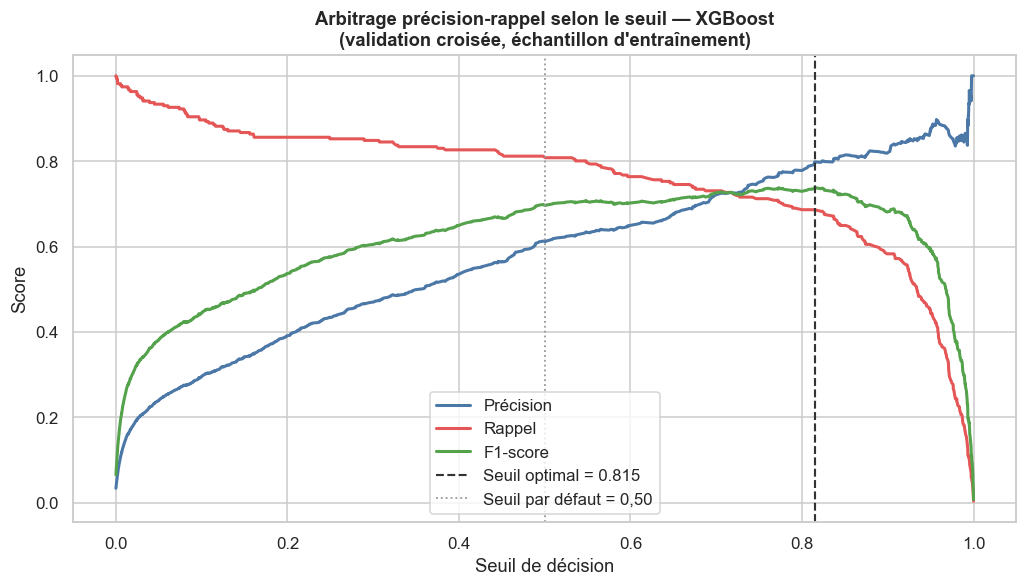

In [18]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(seuils_oof, prec_oof[:-1], label="Précision", color="#4C78A8", linewidth=2)
ax.plot(seuils_oof, rec_oof[:-1], label="Rappel", color="#E45756", linewidth=2)
ax.plot(seuils_oof, f1_oof[:-1], label="F1-score", color="#54A24B", linewidth=2)
ax.axvline(SEUIL_OPTIMAL, color="#333333", linestyle="--", linewidth=1.4,
           label=f"Seuil optimal = {SEUIL_OPTIMAL:.3f}")
ax.axvline(0.5, color="#999999", linestyle=":", linewidth=1.2, label="Seuil par défaut = 0,50")
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("Score")
ax.set_title(f"Arbitrage précision-rappel selon le seuil — {NOM_MEILLEUR}\n(validation croisée, échantillon d'entraînement)",
             fontsize=12, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "10_seuil_decision.png", bbox_inches="tight")
plt.show()

In [19]:
proba_best = meilleur["proba"]
pred_defaut = (proba_best >= 0.5).astype(int)
pred_optimal = (proba_best >= SEUIL_OPTIMAL).astype(int)

comparaison_seuils = pd.DataFrame({
    "Seuil 0,50": {
        "Précision": precision_score(y_test, pred_defaut, zero_division=0),
        "Rappel": recall_score(y_test, pred_defaut),
        "F1": f1_score(y_test, pred_defaut),
        "Pannes manquées": confusion_matrix(y_test, pred_defaut).ravel()[2],
        "Fausses alertes": confusion_matrix(y_test, pred_defaut).ravel()[1],
    },
    f"Seuil {SEUIL_OPTIMAL:.3f}": {
        "Précision": precision_score(y_test, pred_optimal, zero_division=0),
        "Rappel": recall_score(y_test, pred_optimal),
        "F1": f1_score(y_test, pred_optimal),
        "Pannes manquées": confusion_matrix(y_test, pred_optimal).ravel()[2],
        "Fausses alertes": confusion_matrix(y_test, pred_optimal).ravel()[1],
    },
}).round(4)

comparaison_seuils

,"Seuil 0,50",Seuil 0.815
Précision,0.6087,0.8276
Rappel,0.8235,0.7059
F1,0.7000,0.7619
Pannes manquées,12.0000,20.0000
Fausses alertes,36.0000,10.0000


Le seuil retenu (0,815) est nettement supérieur au seuil conventionnel de 0,50. Ce décalage est la conséquence directe de la pondération des classes : en multipliant par 28,5 le poids des pannes dans la fonction de perte, `scale_pos_weight` déplace mécaniquement les probabilités prédites vers le haut. Les conserver telles quelles avec un seuil de 0,50 revient à appliquer deux fois la même correction.

Effet sur le jeu de test :

| | Seuil 0,50 | Seuil 0,815 |
|---|---|---|
| Précision | 0,609 | **0,828** |
| Rappel | 0,824 | 0,706 |
| F1 | 0,700 | **0,762** |
| Pannes manquées | 12 | 20 |
| Fausses alertes | 36 | 10 |

L'ajustement fait passer le F1 de 0,700 à 0,762. Le gain n'est cependant pas gratuit : la précision progresse fortement (0,609 → 0,828) mais **huit pannes supplémentaires échappent à la détection**.

Le F1 accorde un poids identique à la précision et au rappel, ce qui n'a aucune justification métier. Dans un contexte industriel réel, le seuil devrait être fixé à partir du rapport entre le coût d'un arrêt de production subi et celui d'une intervention préventive inutile. Si une panne coûte dix fois plus cher qu'une fausse alerte, le seuil de 0,50 — plus favorable au rappel — reste préférable. **Le seuil est un paramètre métier, pas une constante statistique.**

## 8. Interprétation par valeurs de Shapley

Les valeurs de Shapley décomposent chaque prédiction individuelle en contributions additives attribuées à chaque variable. Contrairement à l'importance par diminution d'impureté fournie nativement par les modèles à base d'arbres, elles sont signées — elles indiquent le *sens* de l'effet — et cohérentes localement comme globalement.

In [20]:
explainer = shap.TreeExplainer(MODELE_MEILLEUR)
shap_values = explainer.shap_values(X_test)

print("Dimensions de la matrice SHAP :", shap_values.shape)
print("Valeur de base (log-odds) :", round(float(explainer.expected_value), 4))

Dimensions de la matrice SHAP : (2000, 7)
Valeur de base (log-odds) : 0.7104


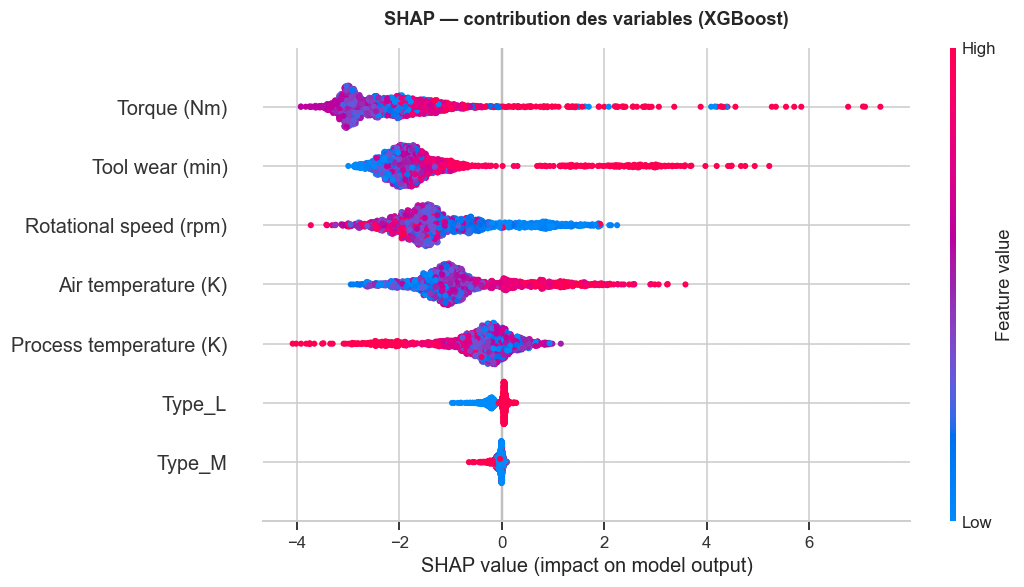

In [21]:
plt.figure()
shap.summary_plot(shap_values, X_test, show=False, plot_size=(10, 5.5))
plt.title(f"SHAP — contribution des variables ({NOM_MEILLEUR})", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(FIG_DIR / "11_shap_summary.png", bbox_inches="tight", dpi=110)
plt.show()

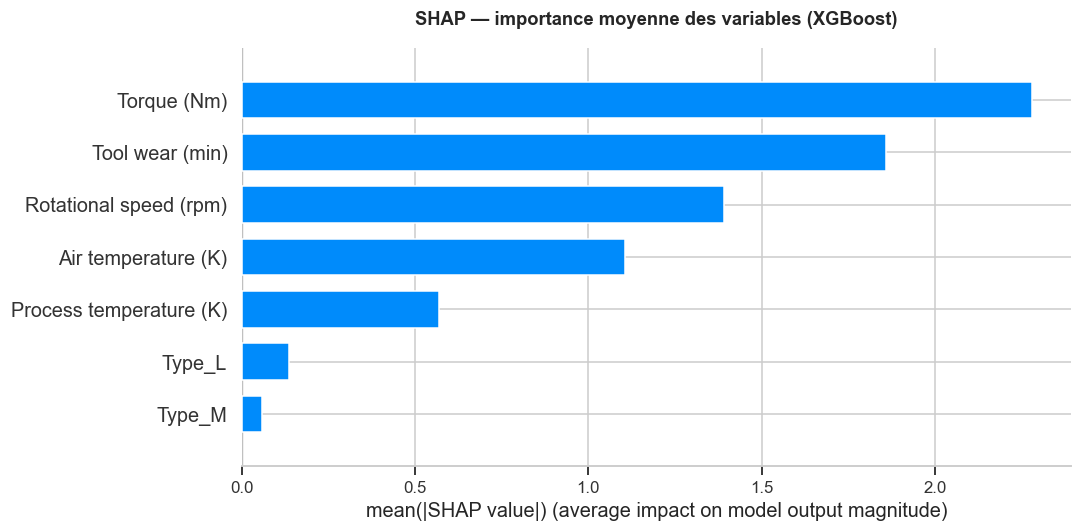

In [22]:
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False, plot_size=(10, 5))
plt.title(f"SHAP — importance moyenne des variables ({NOM_MEILLEUR})", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(FIG_DIR / "12_shap_importance.png", bbox_inches="tight", dpi=110)
plt.show()

In [23]:
importance_shap = (
    pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns)
    .sort_values(ascending=False)
)

pd.DataFrame({
    "Importance SHAP moyenne": importance_shap.round(4),
    "Part relative (%)": (importance_shap / importance_shap.sum() * 100).round(1),
})

,Importance SHAP moyenne,Part relative (%)
Torque (Nm),2.2805,30.799999
Tool wear (min),1.8593,25.100000
Rotational speed (rpm),1.3903,18.799999
Air temperature (K),1.1056,14.900000
Process temperature (K),0.5698,7.700000
Type_L,0.1370,1.900000
Type_M,0.0587,0.800000


### Hiérarchie des variables

| Variable | Part de l'importance totale |
|---|---|
| Torque (Nm) | 30,8 % |
| Tool wear (min) | 25,1 % |
| Rotational speed (rpm) | 18,8 % |
| Air temperature (K) | 14,9 % |
| Process temperature (K) | 7,7 % |
| Type_L | 1,9 % |
| Type_M | 0,8 % |

**Le couple et l'usure de l'outil concentrent 56 % de l'importance totale**, et les trois variables mécaniques — couple, usure, vitesse de rotation — près de 75 %. Ces résultats confirment ce que suggéraient les distributions conditionnelles de l'analyse exploratoire, avec une hiérarchie désormais quantifiée.

**La qualité du produit (`Type`) ne pèse que 2,7 %**, alors que l'analyse exploratoire montrait un taux de panne presque deux fois plus élevé pour les produits de qualité inférieure (3,92 % contre 2,09 %). L'écart s'explique : cet effet est en grande partie *médié* par les conditions de fonctionnement. Les produits de faible qualité sont usinés dans des régimes plus contraignants, déjà décrits par le couple et la vitesse de rotation. Une fois ces variables connues, `Type` n'apporte presque plus d'information. **C'est un exemple de la différence entre corrélation marginale et contribution conditionnelle** — et l'un des apports de SHAP par rapport à une simple analyse bivariée.

**La température du process contribue deux fois moins que la température de l'air** (7,7 % contre 14,9 %). Les deux variables étant corrélées à 0,88, elles portent une information largement redondante ; le modèle s'appuie préférentiellement sur l'une, et la seconde n'ajoute que le résidu. Cette redondance invite à la prudence : l'importance individuelle de variables corrélées se répartit arbitrairement entre elles et ne doit pas être lue comme une mesure de causalité.

### Graphiques de dépendance

Le graphique de dépendance montre comment la contribution d'une variable évolue avec sa valeur, et révèle les effets non linéaires que la régression logistique ne peut pas capter.

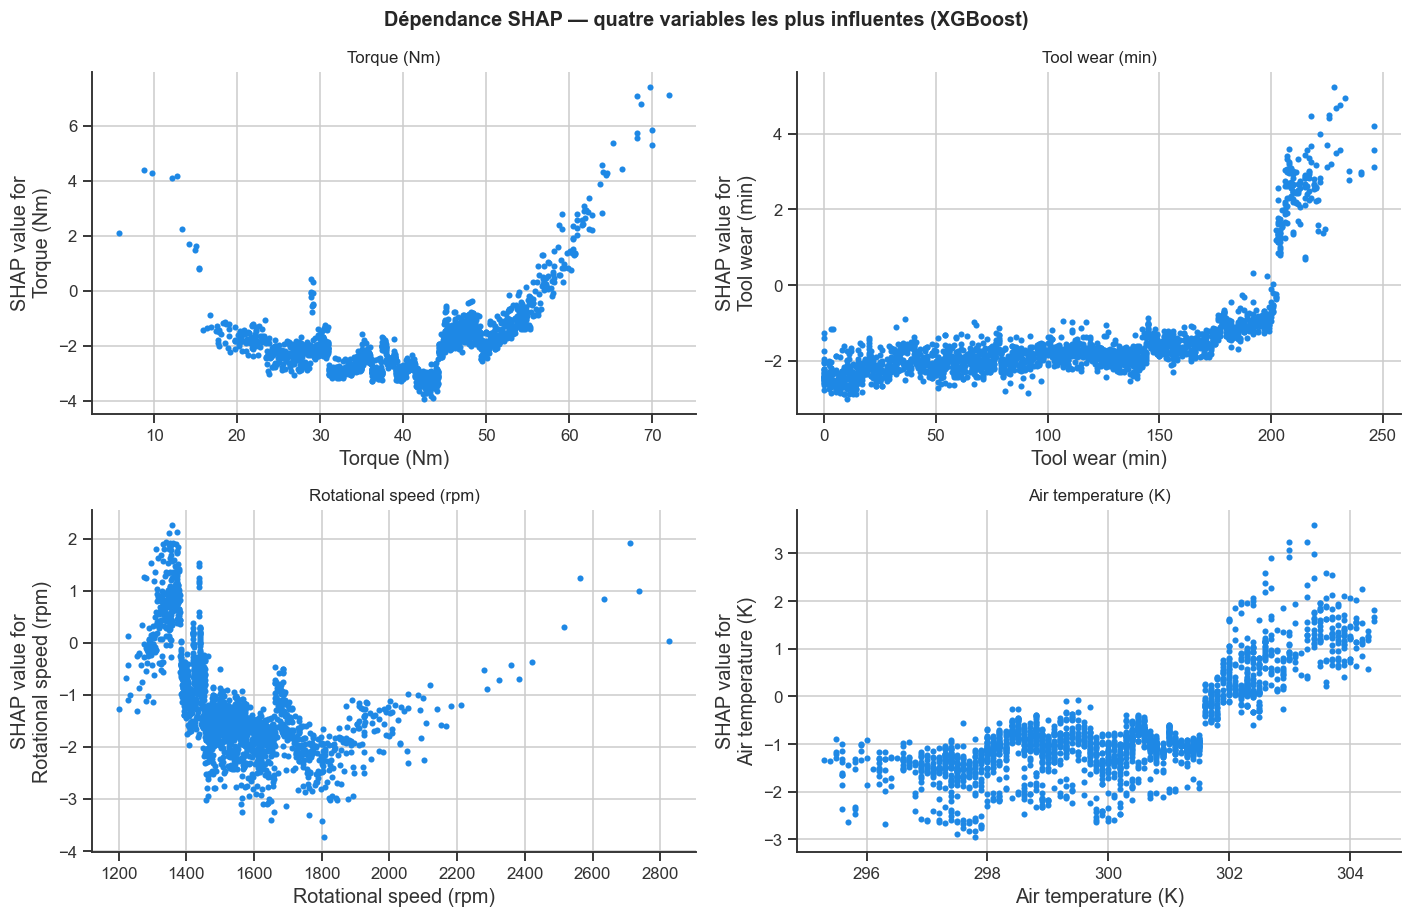

In [24]:
top_features = importance_shap.head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, feature in zip(axes.flat, top_features):
    shap.dependence_plot(feature, shap_values, X_test, ax=ax, show=False, interaction_index=None)
    ax.set_title(feature, fontsize=11)

fig.suptitle(f"Dépendance SHAP — quatre variables les plus influentes ({NOM_MEILLEUR})",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "13_shap_dependence.png", bbox_inches="tight")
plt.show()

### Lecture des dépendances

Les quatre variables présentent des relations franchement non linéaires, que la régression logistique était par construction incapable de représenter.

**Le couple dessine une courbe en U.** La contribution est minimale autour de 40–45 Nm — le régime nominal — et remonte aux deux extrémités : fortement au-delà de 50 Nm, plus modérément en dessous de 15 Nm. C'est la confirmation quantitative des deux régimes de défaillance repérés à l'exploration : **surcharge et sous-charge élèvent toutes deux le risque**. Une frontière linéaire, qui impose un effet monotone, ne peut par nature représenter cette forme — elle doit choisir un sens, et manque nécessairement l'un des deux régimes.

**L'usure de l'outil produit un effet de seuil.** La contribution reste plate et négative sur tout l'intervalle 0–200 minutes, puis bascule brutalement au-delà de 200 minutes. Le modèle a donc appris un **seuil de remplacement implicite**, ce qui correspond à la logique métier : un outil se dégrade sans conséquence jusqu'à un point de rupture. C'est aussi ce qui explique les faux négatifs analysés plus loin — les pannes survenant juste en deçà de ce seuil échappent au modèle.

**La vitesse de rotation reproduit le U du couple, inversé.** Le risque augmente en dessous de 1 400 rpm et au-delà de 2 200 rpm. Couple et vitesse étant mécaniquement liés à puissance donnée, les deux variables décrivent le même phénomène sous deux angles.

**La température de l'air agit également par seuil**, avec une bascule marquée autour de 301,5 K.

Ces quatre formes — deux courbes en U et deux effets de seuil — expliquent en une figure l'écart de performance entre les modèles. **Le problème est non linéaire par nature, et le choix du modèle devait le refléter.**

## 9. Analyse des erreurs

Les métriques agrégées ne disent rien de la nature des observations mal classées. Cette section examine les faux négatifs — pannes non détectées — et les faux positifs — alertes injustifiées — du meilleur modèle au seuil ajusté.

In [25]:
analyse = X_test.copy()
analyse["reel"] = y_test.values
analyse["proba"] = proba_best
analyse["predit"] = pred_optimal

faux_negatifs = analyse[(analyse["reel"] == 1) & (analyse["predit"] == 0)]
faux_positifs = analyse[(analyse["reel"] == 0) & (analyse["predit"] == 1)]
vrais_positifs = analyse[(analyse["reel"] == 1) & (analyse["predit"] == 1)]

print(f"Faux négatifs (pannes manquées)  : {len(faux_negatifs)}")
print(f"Faux positifs (fausses alertes)  : {len(faux_positifs)}")
print(f"Vrais positifs (pannes détectées): {len(vrais_positifs)}")

Faux négatifs (pannes manquées)  : 20
Faux positifs (fausses alertes)  : 10
Vrais positifs (pannes détectées): 48


In [26]:
VARIABLES_PHYSIQUES = list(RENOMMAGE.values())

profils = pd.DataFrame({
    "Vrais négatifs": analyse[(analyse["reel"] == 0) & (analyse["predit"] == 0)][VARIABLES_PHYSIQUES].mean(),
    "Faux positifs": faux_positifs[VARIABLES_PHYSIQUES].mean(),
    "Faux négatifs": faux_negatifs[VARIABLES_PHYSIQUES].mean(),
    "Vrais positifs": vrais_positifs[VARIABLES_PHYSIQUES].mean(),
}).round(2)

profils

,Vrais négatifs,Faux positifs,Faux négatifs,Vrais positifs
Air temperature (K),299.97,301.63,300.94,300.66
Process temperature (K),309.99,310.89,310.44,310.01
Rotational speed (rpm),1539.02,1430.30,1476.30,1480.94
Torque (Nm),39.50,51.93,44.70,52.43
Tool wear (min),107.52,94.40,170.25,146.27


In [27]:
print("Faux négatifs — les pannes les moins bien anticipées (probabilité la plus basse) :")
faux_negatifs.nsmallest(8, "proba")[VARIABLES_PHYSIQUES + ["proba"]].round(3)

Faux négatifs — les pannes les moins bien anticipées (probabilité la plus basse) :


,Air temperature (K),Process temperature (K),Rotational speed (rpm),Torque (Nm),Tool wear (min),proba
9174,297.8,308.9,1871,25.6,200,0.002
1996,298.4,308.0,1416,38.2,198,0.003
8506,298.4,309.6,1710,27.3,163,0.010
2671,299.7,309.3,1399,41.9,221,0.013
7884,300.8,312.4,1465,59.1,91,0.075
2941,300.7,309.6,1996,19.8,203,0.092
3695,302.2,311.3,1530,37.3,207,0.180
7849,300.3,311.7,1374,47.9,222,0.200


In [28]:
print("Faux positifs — les fausses alertes les plus assurées (probabilité la plus élevée) :")
faux_positifs.nlargest(8, "proba")[VARIABLES_PHYSIQUES + ["proba"]].round(3)

Faux positifs — les fausses alertes les plus assurées (probabilité la plus élevée) :


,Air temperature (K),Process temperature (K),Rotational speed (rpm),Torque (Nm),Tool wear (min),proba
3794,302.2,310.8,1356,48.3,36,0.966
4231,302.2,310.8,1340,47.8,54,0.961
4113,302.0,310.6,1325,55.3,192,0.952
1418,298.8,309.9,1320,47.4,210,0.949
6612,301.6,310.6,1222,70.0,62,0.941
7086,300.6,310.4,2514,13.4,215,0.928
4060,302.0,310.9,1352,55.5,59,0.900
3866,302.6,311.6,1311,53.2,0,0.890


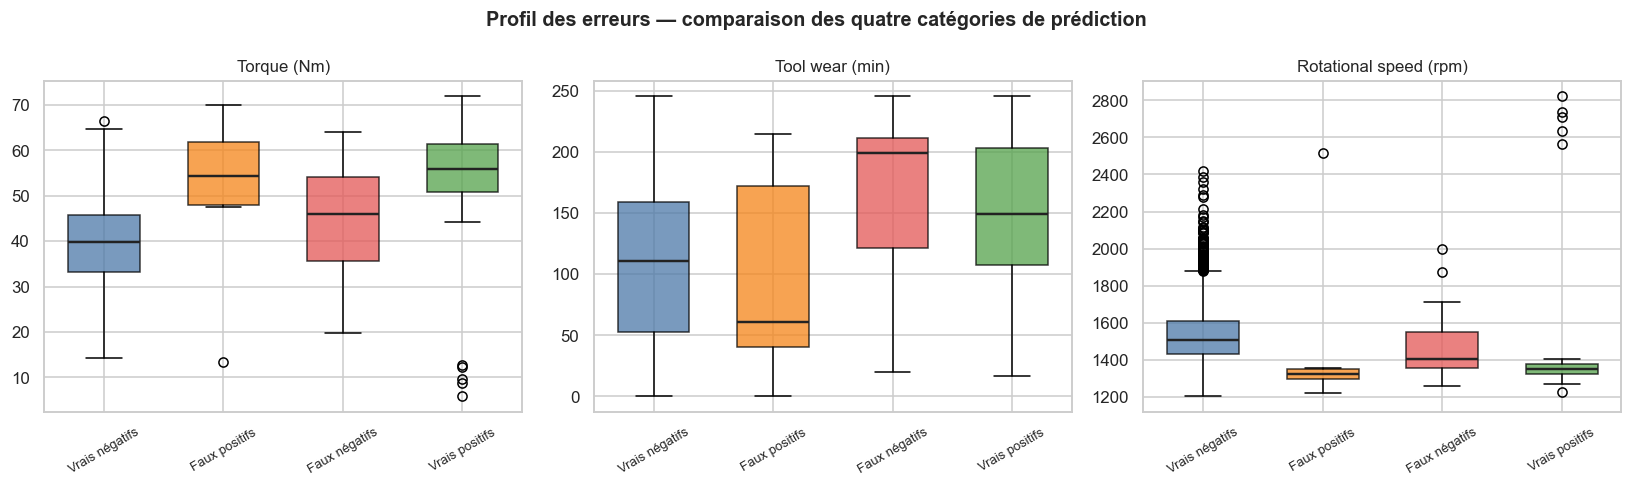

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

categories = {
    "Vrais négatifs": analyse[(analyse["reel"] == 0) & (analyse["predit"] == 0)],
    "Faux positifs": faux_positifs,
    "Faux négatifs": faux_negatifs,
    "Vrais positifs": vrais_positifs,
}
couleurs_cat = {"Vrais négatifs": "#4C78A8", "Faux positifs": "#F58518",
                "Faux négatifs": "#E45756", "Vrais positifs": "#54A24B"}

for ax, var in zip(axes, ["Torque (Nm)", "Tool wear (min)", "Rotational speed (rpm)"]):
    donnees = [g[var].values for g in categories.values()]
    bp = ax.boxplot(donnees, labels=list(categories.keys()), patch_artist=True, widths=0.6)
    for patch, nom in zip(bp["boxes"], categories.keys()):
        patch.set_facecolor(couleurs_cat[nom])
        patch.set_alpha(0.75)
    for mediane in bp["medians"]:
        mediane.set_color("#222222")
        mediane.set_linewidth(1.6)
    ax.set_title(var, fontsize=11)
    ax.tick_params(axis="x", rotation=30, labelsize=8.5)

fig.suptitle("Profil des erreurs — comparaison des quatre catégories de prédiction",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "14_analyse_erreurs.png", bbox_inches="tight")
plt.show()

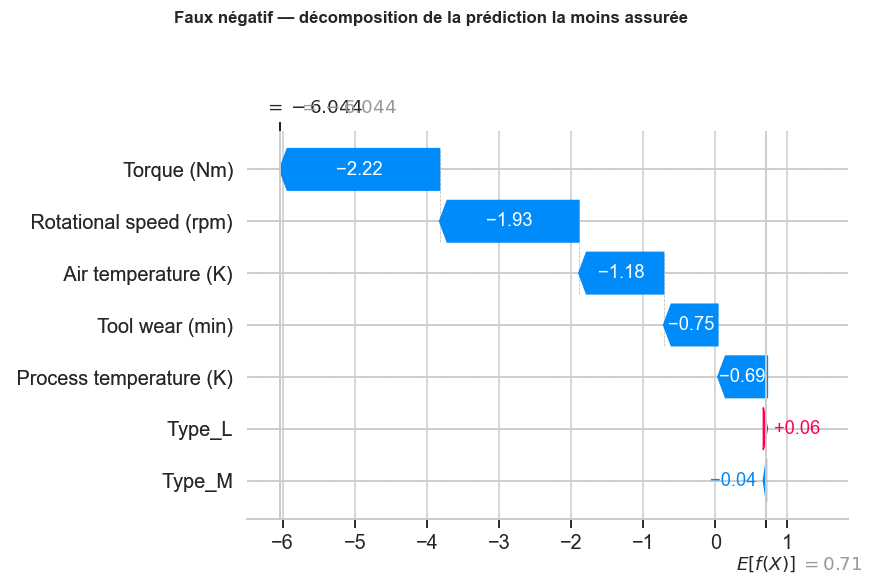

In [30]:
if len(faux_negatifs) > 0:
    idx_fn = faux_negatifs["proba"].idxmin()
    pos_fn = X_test.index.get_loc(idx_fn)
    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        float(explainer.expected_value), shap_values[pos_fn], X_test.iloc[pos_fn], show=False
    )
    plt.gcf().suptitle("Faux négatif — décomposition de la prédiction la moins assurée",
                       fontsize=11, fontweight="bold", y=1.06)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "15_shap_faux_negatif.png", bbox_inches="tight", dpi=110)
    plt.show()

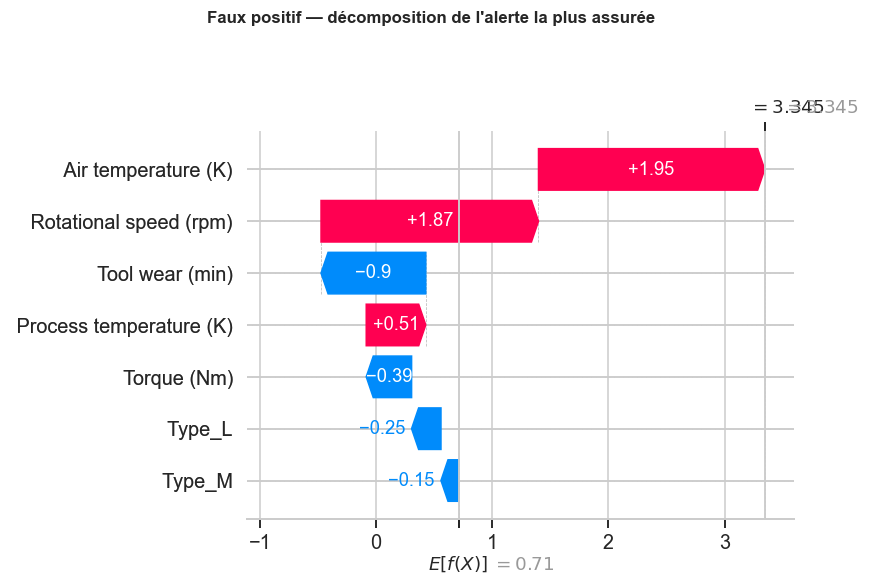

In [31]:
if len(faux_positifs) > 0:
    idx_fp = faux_positifs["proba"].idxmax()
    pos_fp = X_test.index.get_loc(idx_fp)
    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        float(explainer.expected_value), shap_values[pos_fp], X_test.iloc[pos_fp], show=False
    )
    plt.gcf().suptitle("Faux positif — décomposition de l'alerte la plus assurée",
                       fontsize=11, fontweight="bold", y=1.06)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "16_shap_faux_positif.png", bbox_inches="tight", dpi=110)
    plt.show()

### Ce que révèle l'analyse des erreurs

Le profil moyen des quatre catégories de prédiction fait apparaître deux mécanismes d'erreur distincts.

| | Vrais négatifs | Faux positifs | Faux négatifs | Vrais positifs |
|---|---|---|---|---|
| Couple (Nm) | 39,5 | **51,9** | 44,7 | 52,4 |
| Usure de l'outil (min) | 107,5 | 94,4 | **170,3** | 146,3 |
| Vitesse de rotation (rpm) | 1 539 | 1 430 | 1 476 | 1 481 |
| Température de l'air (K) | 300,0 | 301,6 | 300,9 | 300,7 |

**Les faux négatifs sont des pannes d'usure.** Leur usure moyenne (170 minutes) est la plus élevée des quatre catégories — supérieure même à celle des pannes correctement détectées (146 minutes). En revanche leur couple reste modéré (44,7 contre 52,4 pour les vrais positifs). Le détail des cas individuels est sans ambiguïté : usure de 198, 200, 203, 207, 221 et 222 minutes associée à des couples de 19,8 à 41,9 Nm, c'est-à-dire des conditions mécaniques parfaitement ordinaires.

Ces observations correspondent à des défaillances par usure d'outil, qui surviennent en régime normal après un temps d'utilisation prolongé. **Le modèle les manque parce qu'il s'appuie prioritairement sur la contrainte mécanique instantanée** — le couple représente 31 % de son importance — alors que ces pannes relèvent d'un processus cumulatif. Une variable d'interaction entre usure et couple, ou un indicateur d'usure relative au seuil de remplacement, améliorerait probablement leur détection.

**Les faux positifs sont des états à risque qui n'ont pas dégénéré.** Leur profil est celui d'une panne : couple le plus élevé des quatre catégories (51,9 Nm, supérieur même aux vrais positifs), vitesse de rotation la plus basse (1 430 rpm), température de l'air la plus haute. Ce sont des points de fonctionnement en surcharge mécanique — couple élevé à faible vitesse — qui n'ont simplement pas produit de défaillance.

Ces cas ne sont donc pas des erreurs au sens strict : **ils sont physiquement indiscernables des pannes sur la base des variables disponibles.** Un opérateur de maintenance examinant ces machines y trouverait des conditions de fonctionnement effectivement dégradées. Du point de vue métier, une alerte sur ces points relève davantage de la détection précoce que du faux positif.

Deux cas isolés confirment le second régime identifié à l'exploration : l'observation 7086 (couple 13,4 Nm, vitesse 2 514 rpm) et l'observation 9174 parmi les faux négatifs (couple 25,6 Nm, vitesse 1 871 rpm) relèvent de la sous-charge, moins bien apprise faute d'effectifs suffisants dans ce régime.

## 10. Rapport de classification détaillé

In [32]:
print(f"{NOM_MEILLEUR} — seuil {SEUIL_OPTIMAL:.3f}\n")
print(classification_report(y_test, pred_optimal, target_names=["Pas de panne", "Panne"], digits=4))

XGBoost — seuil 0.815

              precision    recall  f1-score   support

Pas de panne     0.9897    0.9948    0.9923      1932
       Panne     0.8276    0.7059    0.7619        68

    accuracy                         0.9850      2000
   macro avg     0.9086    0.8504    0.8771      2000
weighted avg     0.9842    0.9850    0.9844      2000



In [33]:
synthese = tableau.copy()
synthese.loc[f"{NOM_MEILLEUR} (seuil {SEUIL_OPTIMAL:.2f})"] = [
    precision_score(y_test, pred_optimal, zero_division=0),
    recall_score(y_test, pred_optimal),
    f1_score(y_test, pred_optimal),
    average_precision_score(y_test, proba_best),
    roc_auc_score(y_test, proba_best),
]
synthese = synthese.round(4)
synthese.to_csv("../figures/tableau_comparatif.csv")
synthese

,Precision,Recall,F1,PR-AUC,ROC-AUC
Modèle,,,,,
Logistic Regression,0.1418,0.8235,0.2419,0.3817,0.9070
Random Forest,0.8077,0.6176,0.7000,0.7735,0.9709
XGBoost,0.6087,0.8235,0.7000,0.8132,0.9723
XGBoost (seuil 0.81),0.8276,0.7059,0.7619,0.8132,0.9723


## Conclusions

### Réponse à la question de recherche

> *Dans quelle mesure des modèles de Machine Learning permettent-ils de détecter efficacement les risques de panne, et quels facteurs influencent le plus leurs prédictions ?*

**Sur l'efficacité de la détection.** XGBoost atteint une PR-AUC de 0,813 contre 0,034 pour un classifieur aléatoire, soit un pouvoir de discrimination vingt-quatre fois supérieur au hasard. Au seuil ajusté, il détecte 48 pannes sur 68 en n'émettant que 10 fausses alertes. La détection automatique des risques de panne est donc opérationnellement viable sur ce jeu de données, à condition de calibrer le seuil sur l'arbitrage métier plutôt que sur une convention statistique.

**Sur les facteurs déterminants.** Trois variables mécaniques concentrent 75 % de l'importance : le couple (30,8 %), l'usure de l'outil (25,1 %) et la vitesse de rotation (18,8 %). Les températures suivent (22,6 % à elles deux), la qualité du produit est marginale (2,7 %) une fois les conditions de fonctionnement connues.

### Validité de l'hypothèse

L'hypothèse était partiellement exacte. Les modèles non linéaires détectent effectivement bien mieux les pannes — la PR-AUC passe de 0,382 à 0,813. Mais la crainte d'un surcroît de faux positifs était infondée : XGBoost en produit neuf fois moins que la régression logistique (36 contre 339 au seuil par défaut).

L'écart s'explique par la géométrie du problème plutôt que par la capacité des modèles. Les pannes surviennent dans deux régimes opposés — surcharge et sous-charge — qu'aucun hyperplan ne peut isoler simultanément sans englober la zone centrale où se concentrent les observations saines.

### Choix du modèle

**XGBoost** est retenu : meilleure PR-AUC (0,813 contre 0,774), et meilleur rappel à précision comparable une fois le seuil ajusté. La validation croisée place toutefois Random Forest à un niveau statistiquement équivalent (0,750 contre 0,751, pour des écarts-types de l'ordre de 0,036) : l'écart observé sur le jeu de test tient en partie à l'échantillon particulier de test et ne doit pas être présenté comme une supériorité établie.

### Limites

**Liées aux données**

- Le jeu de données est **synthétique**. Les relations entre variables y sont générées par des règles déterministes, plus régulières que ce qu'on observerait sur des capteurs réels soumis au bruit, à la dérive et aux valeurs manquantes.
- **9 pannes sur 339 ne sont associées à aucun mode de défaillance identifié**, et 18 observations portent un mode `RNF` (panne aléatoire) sans étiquette de panne. Ces cas, non prédictibles par construction, abaissent le plafond de performance atteignable.
- **68 pannes seulement dans le jeu de test.** Chaque observation mal classée déplace le rappel de 1,5 point : les intervalles de confiance sur les métriques sont larges et les écarts faibles entre modèles doivent être interprétés avec prudence.
- Les **observations sont supposées indépendantes**. S'il s'agissait de relevés successifs d'une même machine, cette hypothèse serait violée et la séparation train/test aléatoire produirait une fuite temporelle.

**Liées au protocole**

- Les **hyperparamètres ne sont pas optimisés**. Aucune recherche systématique n'a été conduite ; les valeurs retenues sont des choix raisonnables mais non justifiés empiriquement.
- **Aucune ingénierie de variables** n'a été réalisée, alors que les modes de défaillance du dataset sont définis à partir de grandeurs dérivées — puissance mécanique (produit du couple et de la vitesse), écart entre les deux températures. Les construire explicitement améliorerait vraisemblablement la détection, en particulier celle des pannes d'usure actuellement manquées.
- Le **seuil est optimisé sur le F1**, qui pondère identiquement précision et rappel. Ce choix n'a pas de fondement métier : il devrait dériver du rapport entre coût d'un arrêt subi et coût d'une intervention inutile.
- La **colinéarité entre les deux températures** (r ≈ 0,88) et entre couple et vitesse de rotation (r ≈ −0,88) répartit arbitrairement l'importance SHAP entre variables redondantes. Ces valeurs mesurent une contribution au sein du modèle, non une relation causale.

### Prolongements

1. Construire les variables dérivées (puissance mécanique, écart de températures, interaction usure × couple) et mesurer leur apport par ablation.
2. Optimiser les hyperparamètres par recherche aléatoire avec validation croisée, en maximisant la PR-AUC.
3. Substituer au F1 une fonction de coût métier explicite et en déduire le seuil optimal.
4. Reproduire le protocole sur des données industrielles réelles pour éprouver la validité externe des conclusions.